In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.datasets import imdb
from keras.utils import pad_sequences
print("Keras:", keras.__version__)

Keras: 3.13.2


In [2]:
VOCAB, MAXLEN = 10000, 200
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=VOCAB)
x_train = pad_sequences(x_train, maxlen=MAXLEN)
x_test = pad_sequences(x_test, maxlen=MAXLEN)
print("Train:", x_train.shape, "| Test:", x_test.shape, "| Labels:", np.unique(y_train))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (25000, 200) | Test: (25000, 200) | Labels: [0 1]


In [3]:
def build(kind):
    cell = layers.LSTM(64) if kind == "LSTM" else layers.SimpleRNN(64)
    model = keras.Sequential([
        layers.Input(shape=(MAXLEN,)),
        layers.Embedding(VOCAB, 64),
        cell,
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ], name=kind)
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

build("LSTM").summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
histories, scores = {}, {}
for kind in ["SimpleRNN", "LSTM"]:
    print(f"\n===== Training {kind} =====")
    m = build(kind)
    histories[kind] = m.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.2, verbose=2)
    scores[kind] = m.evaluate(x_test, y_test, verbose=0)[1]
    globals()["model_" + kind] = m
print("\nTest accuracy:", {k: round(v, 4) for k, v in scores.items()})


===== Training SimpleRNN =====
Epoch 1/3
157/157 - 10s - 61ms/step - accuracy: 0.5827 - loss: 0.6616 - val_accuracy: 0.7558 - val_loss: 0.4990
Epoch 2/3
157/157 - 3s - 18ms/step - accuracy: 0.8237 - loss: 0.4069 - val_accuracy: 0.8354 - val_loss: 0.3820
Epoch 3/3
157/157 - 3s - 18ms/step - accuracy: 0.9198 - loss: 0.2155 - val_accuracy: 0.8368 - val_loss: 0.3962

===== Training LSTM =====
Epoch 1/3
157/157 - 7s - 46ms/step - accuracy: 0.7719 - loss: 0.4755 - val_accuracy: 0.8616 - val_loss: 0.3313
Epoch 2/3
157/157 - 3s - 20ms/step - accuracy: 0.8971 - loss: 0.2632 - val_accuracy: 0.8730 - val_loss: 0.3001
Epoch 3/3
157/157 - 4s - 26ms/step - accuracy: 0.9248 - loss: 0.2004 - val_accuracy: 0.8768 - val_loss: 0.3158

Test accuracy: {'SimpleRNN': 0.834, 'LSTM': 0.8646}


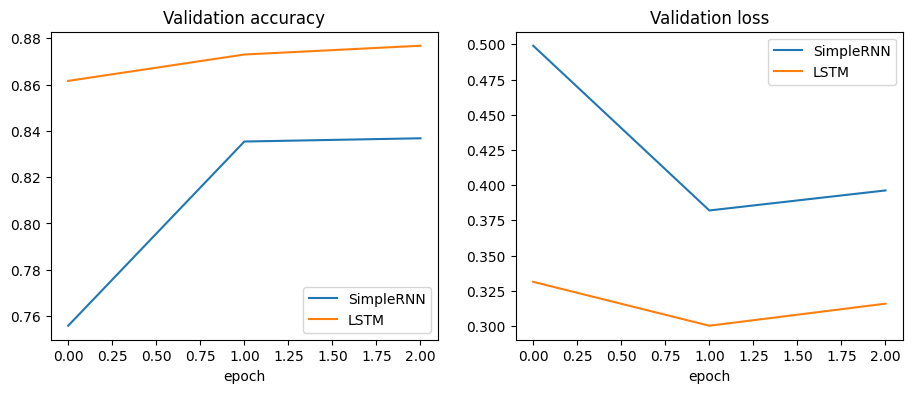

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for kind, h in histories.items():
    ax[0].plot(h.history["val_accuracy"], label=kind)
    ax[1].plot(h.history["val_loss"], label=kind)
ax[0].set_title("Validation accuracy"); ax[1].set_title("Validation loss")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.show()

In [6]:
word_index = imdb.get_word_index()
def encode(text):
    ids = [1]                                        # 1 = start token
    for w in text.lower().replace(".", "").replace(",", "").replace("!", "").split():
        i = word_index.get(w)
        ids.append(i + 3 if i is not None and i + 3 < VOCAB else 2)   # 2 = unknown
    return pad_sequences([ids], maxlen=MAXLEN)

for review in ["This movie was fantastic, I loved the acting and the story",
               "Terrible film, boring plot and awful acting, a waste of time"]:
    p = float(model_LSTM.predict(encode(review), verbose=0)[0][0])
    print(f"{'Positive' if p > 0.5 else 'Negative'} ({p:.2f}) <- {review}")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Positive (0.78) <- This movie was fantastic, I loved the acting and the story
Negative (0.00) <- Terrible film, boring plot and awful acting, a waste of time
